# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170352          # <-- your full roll number
NAME = "Rahil Kapoor"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170352   Name: Rahil Kapoor   Fingerprint: 880FE173   Tickets: 14

Ticket_ID                                                                Ticket_Text
      T01                                  The printer won't print; it isn't jammed.
      T02     The student portal keeps asking for login. I have tried several times!
      T03                                                The file is 95.5% uploaded.
      T04                         The Python keeps asking for login. This is urgent.
      T05     Printer is running slowly since yesterday. I have tried several times!
      T06                                              The LMS says 'Not Submitted'.
      T07   I was locked out of the VPN when connected to campus Wi-Fi. Please help.
      T08    Printer keeps disconnecting since yesterday. Is there another solution?
      T09    Python has stopped syncing on my laptop. The same problem occurs again.
      T10                               Call me on +91 98765 43210

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Q1: Preprocessing pipeline

import pandas as pd

rows = []
all_tokens = []
all_punct = []
all_stops = []
all_final = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    tokens = result["tokens"]
    final = result["final"]

    all_tokens.extend(tokens)
    all_punct.extend(result["punct"])
    all_stops.extend(result["stops"])
    all_final.extend(final)

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": result["sentences"],
        "Tokens": tokens,
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique Tokens": sorted(set(tokens)),
        "Final Tokens": final
    })

q1_table = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(process_ticket(t)["sentences"])
                     for t in df["Ticket_Text"]),
    "Tokens": len(all_tokens),
    "Punctuation": len(all_punct),
    "Stopwords": len(all_stops),
    "Unique Tokens": len(set(all_tokens)),
    "Final Tokens": len(all_final)
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,[The printer won't print; it isn't jammed.],"[the, printer, wo, n't, print, ;, it, is, n't,...","[;, .]","[the, it, is]","[., ;, is, it, jammed, n't, print, printer, th...","[printer, wo, n't, print, n't, jammed]"
1,T02,"[The student portal keeps asking for login., I...","[the, student, portal, keeps, asking, for, log...","[., !]","[the, for, i, have]","[!, ., asking, for, have, i, keeps, login, por...","[student, portal, keeps, asking, login, tried,..."
2,T03,[The file is 95.5% uploaded.],"[the, file, is, 95.5, %, uploaded, .]","[%, .]","[the, is]","[%, ., 95.5, file, is, the, uploaded]","[file, 95.5, uploaded]"
3,T04,"[The Python keeps asking for login., This is u...","[the, python, keeps, asking, for, login, ., th...","[., .]","[the, for, this, is]","[., asking, for, is, keeps, login, python, the...","[python, keeps, asking, login, urgent]"
4,T05,"[Printer is running slowly since yesterday., I...","[printer, is, running, slowly, since, yesterda...","[., !]","[is, i, have]","[!, ., have, i, is, printer, running, several,...","[printer, running, slowly, since, yesterday, t..."
5,T06,[The LMS says 'Not Submitted'.],"[the, lms, says, 'not, submitted, ', .]","[', .]",[the],"[', 'not, ., lms, says, submitted, the]","[lms, says, 'not, submitted]"
6,T07,[I was locked out of the VPN when connected to...,"[i, was, locked, out, of, the, vpn, when, conn...","[., .]","[i, was, out, of, the, when, to]","[., campus, connected, help, i, locked, of, ou...","[locked, vpn, connected, campus, wi-fi, please..."
7,T08,"[Printer keeps disconnecting since yesterday.,...","[printer, keeps, disconnecting, since, yesterd...","[., ?]","[is, there]","[., ?, another, disconnecting, is, keeps, prin...","[printer, keeps, disconnecting, since, yesterd..."
8,T09,"[Python has stopped syncing on my laptop., The...","[python, has, stopped, syncing, on, my, laptop...","[., .]","[has, on, my, the, same, again]","[., again, has, laptop, my, occurs, on, proble...","[python, stopped, syncing, laptop, problem, oc..."
9,T10,[Call me on +91 98765 43210 or 0175-239-3201.],"[call, me, on, +91, 98765, 43210, or, 0175-239...",[.],"[me, on, or]","[+91, ., 0175-239-3201, 43210, 98765, call, me...","[call, +91, 98765, 43210, 0175-239-3201]"


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens are not complete words, such as “n't”, “'s”, and “ca”. They come from contractions like “isn't” and “can't”, which NLTK's `word_tokenize()` splits into separate tokens. Since stopword removal is performed on individual tokens, some fragments may remain in the final tokens if they are not present in the stopword list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Q2: Regular expressions

import re

# Extract patterns
patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)*(?![\w.])",
    "Capitalized words": r"\b[A-Z][A-Za-z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

# Combine TEST_LINES and raw ticket texts
all_lines = list(TEST_LINES) + df["Ticket_Text"].tolist()

for name, pattern in patterns.items():
    print(f"\n{name}:")
    for line in all_lines:
        matches = re.findall(pattern, line)
        if matches:
            print(matches)

# Redact sensitive information
email_pattern = (
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
url_pattern = r"https?://[^\s<>]+|www\.[^\s<>]+"

phone_pattern = (
    r"(?<!\w)(?:\+91[\s-]?)?"
    r"(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})"
    r"(?!\w)"
)

def redact_text(text):
    text = re.sub(email_pattern, "[EMAIL]", text, flags=re.I)
    text = re.sub(url_pattern, "[URL]", text, flags=re.I)
    text = re.sub(phone_pattern, "[PHONE]", text)
    return text

print("\nRedacted TEST_LINES:")
for line in TEST_LINES:
    print(redact_text(line))

print("\nRedacted tickets:")
for text in df["Ticket_Text"]:
    print(redact_text(text))


Words longer than 5 letters:
['helpdesk', 'thapar', 'thapar', 'thapar']
['Version']
['printer', 'jammed']
['student', 'portal', 'asking', 'several']
['uploaded']
['Python', 'asking', 'urgent']
['Printer', 'running', 'slowly', 'yesterday', 'several']
['Submitted']
['locked', 'connected', 'campus', 'Please']
['Printer', 'disconnecting', 'yesterday', 'another', 'solution']
['Python', 'stopped', 'syncing', 'laptop', 'problem', 'occurs']
['Python', 'asking', 'urgent']
['Projector', 'failed', 'latest', 'update', 'worked', 'yesterday']
['during']
['crashes', 'opening', 'mobile', 'hotspot']

Numbers:
['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '2.0.1', '95.5', '1']
['5.30']
['95.5']
['91', '98765', '43210', '0175', '239']

Capitalized words:
['Mail']
['Call', 'Version', 'Rs']
['The']
['The']
['The', 'I']
['The']
['The', 'Python', 'This']
['Printer', 'I']
['The', 'LMS', 'Not', 'Submitted']
['I', 'VPN', 'Wi', 'Fi', 'Please']
['Printer', 'Is']
['Python', 'The']
['Call']
['The

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Many capitalized words are capitalized only because they appear at the beginning of a sentence, such as “The,” “Please,” and “I.” Other words, such as “Python,” “MATLAB,” and “Wi-Fi,” are capitalized because they are names or technical terms. The exact number of sentence-initial words can be determined by comparing the regex results with their positions in the original tickets.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
# Q3: Custom tokenizer

from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"https?://[^\s<>]+|www\.[^\s<>]+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"\+?\d[\d\s().-]*\d|"
    r"\d+(?:\.\d+)+|\d+\.\d+|"
    r"[A-Za-z]+(?:[-'][A-Za-z]+)+|"
    r"[A-Za-z]+|"
    r"\d+|"
    r"[^\w\s]"
)

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

# Test on the supplied lines
for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Custom:  ", my_tokenize(line))
    print("NLTK:    ", word_tokenize(line))

# Compare tokenization for every ticket
comparison_rows = []

for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    nltk_tokens = word_tokenize(row["Ticket_Text"])

    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Custom Tokens": custom,
        "NLTK Tokens": nltk_tokens,
        "Different": custom != nltk_tokens
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison)

print(
    "Tickets tokenized differently:",
    comparison["Different"].sum(),
    "out of",
    len(comparison)

)
print(comparison["Different"].sum(), "out of", len(comparison))


Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK:     ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK:     ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom:   

,Ticket_ID,Custom Tokens,NLTK Tokens,Different
0,T01,"[The, printer, won't, print, ;, it, isn't, jam...","[The, printer, wo, n't, print, ;, it, is, n't,...",True
1,T02,"[The, student, portal, keeps, asking, for, log...","[The, student, portal, keeps, asking, for, log...",False
2,T03,"[The, file, is, 95.5, %, uploaded, .]","[The, file, is, 95.5, %, uploaded, .]",False
3,T04,"[The, Python, keeps, asking, for, login, ., Th...","[The, Python, keeps, asking, for, login, ., Th...",False
4,T05,"[Printer, is, running, slowly, since, yesterda...","[Printer, is, running, slowly, since, yesterda...",False
5,T06,"[The, LMS, says, ', Not, Submitted, ', .]","[The, LMS, says, 'Not, Submitted, ', .]",True
6,T07,"[I, was, locked, out, of, the, VPN, when, conn...","[I, was, locked, out, of, the, VPN, when, conn...",False
7,T08,"[Printer, keeps, disconnecting, since, yesterd...","[Printer, keeps, disconnecting, since, yesterd...",False
8,T09,"[Python, has, stopped, syncing, on, my, laptop...","[Python, has, stopped, syncing, on, my, laptop...",False
9,T10,"[Call, me, on, +91 98765 43210, or, 0175-239-3...","[Call, me, on, +91, 98765, 43210, or, 0175-239...",True


Tickets tokenized differently: 4 out of 14
4 out of 14


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*4/14


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
# Q4: Stemming and lemmatization

import re
import nltk
import pandas as pd

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()

# A deliberately simple suffix rule for comparison
regex_stemmer = RegexpStemmer(
    r"(ing|ed|ies|s)$",
    min=4
)

lemmatizer = WordNetLemmatizer()

def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"  # adjective
    elif tag.startswith("V"):
        return "v"  # verb
    elif tag.startswith("N"):
        return "n"  # noun
    elif tag.startswith("R"):
        return "r"  # adverb
    return "n"

# Get unique final tokens from all tickets
unique_final_tokens = sorted(set(
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
))

# POS-tag the words
tagged_words = pos_tag(unique_final_tokens)

rows = []

for word, pos in tagged_words:
    wn_pos = penn_to_wordnet(pos)

    rows.append({
        "Word": word,
        "POS": pos,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regex_stemmer.stem(word),
        "Lemma": lemmatizer.lemmatize(word, pos=wn_pos)
    })

stem_table = pd.DataFrame(rows)

# Show words for which at least one output differs
output_columns = ["Porter", "Lancaster", "Regexp", "Lemma"]

different_words = stem_table[
    stem_table[output_columns].nunique(axis=1) > 1
]

display(different_words)

,Word,POS,Porter,Lancaster,Regexp,Lemma
6,another,DT,anoth,anoth,another,another
9,call,VB,call,cal,call,call
10,campus,NN,campu,camp,campu,campus
13,crashes,NNS,crash,crash,crashe,crash
16,file,NN,file,fil,file,file
19,jammed,VBD,jam,jam,jamm,jam
23,latest,JJS,latest,latest,latest,late
24,lms,NN,lm,lms,lms,lm
27,mobile,NN,mobil,mobl,mobile,mobile
29,occurs,VBD,occur,occ,occur,occur


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* **Over-stemming:** LancasterStemmer may reduce “maximum” to “maxim,” which can be an overly aggressive reduction.

**Under-stemming:** The words “connection” and “connectivity” may remain different stems even though they are related in meaning.

Over-stemming removes too much of a word, while under-stemming fails to combine related words. The exact examples should be verified against the outputs in my stemming table.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 (All tokens),167,91,0.5449
1,S2 (No punctuation),140,85,0.6071
2,S3 (Final tokens),84,60,0.7143
3,S4 (Porter stems),84,59,0.7024



Top 10 words in S1:
[('.', 19), ('the', 11), ('is', 6), ('i', 5), ('keeps', 4), ('this', 4), ('printer', 3), ("n't", 3), ('asking', 3), ('for', 3)]

Top 10 words in S3:
[('keeps', 4), ('printer', 3), ("n't", 3), ('asking', 3), ('login', 3), ('python', 3), ('yesterday', 3), ('tried', 2), ('several', 2), ('times', 2)]


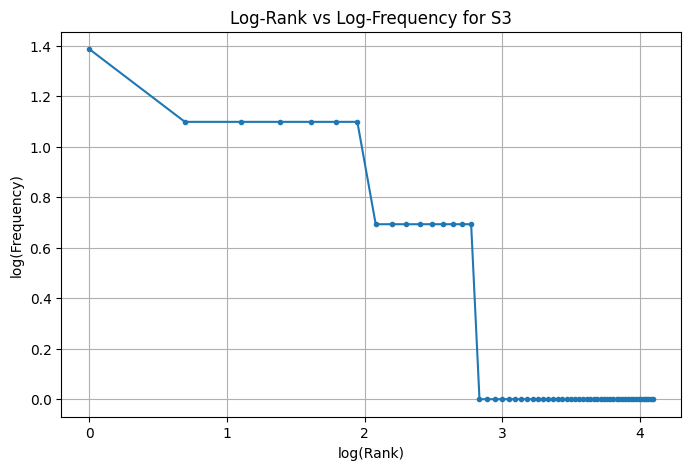


Top 5 bigrams in S1:
[(('.', 'the'), 4), (('.', 'i'), 4), (('keeps', 'asking'), 3), (('asking', 'for'), 3), (('for', 'login'), 3)]

Top 5 bigrams in S3:
[(('keeps', 'asking'), 3), (('asking', 'login'), 3), (('tried', 'several'), 2), (('several', 'times'), 2), (('python', 'keeps'), 2)]


In [9]:
# Q5: Corpus statistics

import math
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.util import bigrams

# Build the corpora from the official pipeline
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)

    S1.extend(result["tokens"])
    S2.extend(t for t in result["tokens"] if not is_punct(t))
    S3.extend(result["final"])

S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1 (All tokens)": S1,
    "S2 (No punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (Porter stems)": S4
}

# Corpus statistics
stats = []

for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

# Top 10 words in S1 and S3
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

# Log(rank) versus log(frequency) for S3
freq = Counter(S3).most_common()

ranks = list(range(1, len(freq) + 1))
frequencies = [count for word, count in freq]

log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [math.log(count) for count in frequencies]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o", markersize=3)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log-Rank vs Log-Frequency for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams in S1 and S3
print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because punctuation and stopwords are removed, and Porter stemming combines related word forms into common stems. These operations change the number of total tokens and unique tokens. Removing frequent stopwords can increase TTR, while stemming generally reduces vocabulary diversity by merging word forms. Therefore, TTR may increase or decrease depending on the dataset.